# Do Explanations Survive the Camera?
## Cross-site attribution consistency in diabetic retinopathy screening

**Author:** Sadaf Zehra · pilot study

**Question.** A diabetic retinopathy (DR) classifier trained at one site is often tested at another site with a different fundus camera. Accuracy may hold up, but does the model still look at the *same evidence* (lesions) when the camera changes? Recent work measures attribution consistency across demographic groups; this notebook asks the same question across **acquisition sites / devices**.

**What the notebook does**
1. Trains two models on one source site (APTOS 2019) for *referable DR* (ICDR grade ≥ 2):
   - **ResNet-50 + Grad-CAM** (post-hoc explanation)
   - **ResNet-50 Evidence-Map model** (inherently interpretable: a 1×1 conv produces a class-evidence map and the logit is the spatial mean of that map, so the map is an exact additive decomposition of the decision)
2. Tests both on external sites (IDRiD, Messidor-2) and reports AUC with bootstrap CIs.
3. Measures **where** each model looks at every site:
   - attribution energy *outside* the retina (a shortcut indicator)
   - spread (entropy) and centre-of-mass of the attribution
   - distribution shift of these statistics vs. the source site (Wasserstein, KS test)
4. **Lesion grounding** on IDRiD pixel-level lesion masks (energy-in-lesion, lift over area, pointing game, AUPRC).
5. **Paired site-swap test:** the *same* image is re-coloured to look like each target site (FOV-restricted histogram matching), and the two explanations are compared (Spearman rank correlation, top-10% IoU, prediction flips).
6. **Deletion test** (faithfulness): removing the most-attributed patches should hurt the prediction more than removing random patches.

**This version runs on Kaggle Notebooks** (free GPU, datasets attached with *Add Input*, no API key or download needed). Mixed precision and cached 384 px images keep it fast.

## How to use (Kaggle)

1. **Phone verification (one time):** Kaggle → Settings → *Phone Verification*. Kaggle needs this before it gives you a GPU and internet.
2. Right panel → **Session options**: *Accelerator* = **GPU T4 x2** (the code uses one GPU), *Internet* = **On** (needed once to download the ImageNet ResNet-50 weights).
3. **Data downloads automatically** with `kagglehub` (inside Kaggle you are already logged in, no key needed):
   - **APTOS 2019**: accept the competition rules once at https://www.kaggle.com/competitions/aptos2019-blindness-detection/rules
   - **IDRiD**: a Kaggle copy of the dataset is downloaded. If that copy ever disappears, attach any IDRiD dataset with *Add Input* (it must contain *A. Segmentation* and *B. Disease Grading*), or put its name in `IDRID_SLUGS`.
   - optional **Messidor-2**: images are not on Kaggle (redistribution is not allowed). If you have them, upload them as your own **private** dataset and attach it together with *MESSIDOR-2 DR Grades* (Google Brain). Without Messidor-2 the study runs on APTOS + IDRiD.
4. First run with `DEMO_MODE = True` (synthetic data, about 10 minutes). Then set `DEMO_MODE = False`.
5. For the full run use **Save Version → Save & Run All (Commit)**. It runs in the background (you can close the browser, max 12 h) and keeps everything in `/kaggle/working/fundus_xai/outputs/` as the notebook's *Output*.

Kaggle gives about 30 GPU hours per week. One full run of this notebook needs well under that.

In [1]:
# --- General imports (all pre-installed on Kaggle) ---
import os, re, sys, glob, json, math, random, time, shutil, zipfile, warnings, subprocess
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats, ndimage
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x
try:
    from IPython.display import display
except ImportError:
    display = print

def walk_files(root, name_pattern="*"):
    """Recursive file search that also enters symlinked folders (Kaggle mounts inputs this way)."""
    import fnmatch
    for dirpath, _, files in os.walk(str(root), followlinks=True):
        for f in files:
            if fnmatch.fnmatch(f, name_pattern):
                yield Path(dirpath) / f

def walk_dirs(root):
    for dirpath, dirs, _ in os.walk(str(root), followlinks=True):
        for d in dirs:
            yield Path(dirpath) / d

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# --- PyTorch ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU nahi mila. Right panel > Session options > Accelerator > GPU T4 x2 select karein.")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
torch.backends.cudnn.benchmark = True
USE_AMP = DEVICE == "cuda"

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda
GPU: Tesla T4


In [3]:
# ======================= CONFIG =======================
DEMO_MODE = False        # pehle True: synthetic data par poora pipeline test. Phir False for the real study.
FORCE_RETRAIN = False   # True karein agar saved checkpoint ke bajaye dobara train karna ho

CFG = dict(
    img_size=384,          # 384 is a good balance for T4 (lesions are small; 224 loses them)
    batch_size=16,
    epochs=12,
    lr=3e-4,
    weight_decay=1e-4,
    warmup_epochs=1,
    patience=4,            # early stopping on validation AUC
    num_workers=min(4, os.cpu_count() or 2),
    dilate_layer4=True,    # stride-16 feature maps (24x24 at 384 px) -> sharper explanations
    evidence_l1=1e-4,      # sparsity on the evidence maps of the interpretable model
    val_frac=0.15,
    test_frac=0.15,
    seed=42,
    fov_thresh=12,         # pixel intensity threshold for the retina field-of-view mask
    n_bootstrap=500,
    max_eval_per_site=None,  # e.g. 600 to make evaluation faster
    n_swap=200,            # images used in the paired site-swap test
    swap_ref_pool=40,      # reference images per target site for colour matching
    n_deletion=150,
    pool=8,                # pooling factor for map comparisons (384/8 = 48x48)
)
if DEMO_MODE:
    CFG.update(img_size=224, epochs=3, batch_size=16, patience=2, n_bootstrap=100,
               n_swap=40, swap_ref_pool=10, n_deletion=30, pool=4)

# --- Paths on Kaggle: attached datasets are read-only in /kaggle/input; everything we write goes to /kaggle/working ---
ON_KAGGLE = Path("/kaggle/input").exists()
INPUT = Path("/kaggle/input") if ON_KAGGLE else Path("./kaggle_input")
BASE = Path("/kaggle/working/fundus_xai") if ON_KAGGLE else Path("./fundus_xai")
RAW = BASE / "raw"             # only used for the synthetic DEMO data

CACHE = BASE / f"cache_{'demo_' if DEMO_MODE else ''}{CFG['img_size']}"
OUT = BASE / ("outputs_demo" if DEMO_MODE else "outputs")
for p in [RAW, CACHE, OUT]:
    p.mkdir(parents=True, exist_ok=True)

SOURCE_SITE = "APTOS"

# Each site: root folder (searched recursively), CSV pattern, column names.
# The roots are found automatically inside /kaggle/input in the "Data" cell below.
SITES = {
    "APTOS": dict(root=INPUT, csv_glob="**/train.csv",
                  id_col="id_code", label_col="diagnosis"),
    "IDRiD": dict(root=INPUT, csv_glob="**/*.csv",
                  id_col="Image name", label_col="Retinopathy grade"),
    "Messidor-2": dict(root=INPUT, csv_glob="**/messidor_data.csv",
                       id_col="image_id", label_col="adjudicated_dr_grade",
                       filter_col="adjudicated_gradable", filter_val=1),
}
# IDRiD pixel-level lesion masks (A. Segmentation): MA, HE, EX, SE = lesions, OD = optic disc
SEG = dict(name="IDRiD-Seg", root=INPUT,
           lesion_suffixes=["MA", "HE", "EX", "SE"], od_suffix="OD")

print("BASE :", BASE)
print("CACHE:", CACHE)
print("OUT  :", OUT)

BASE : /kaggle/working/fundus_xai
CACHE: /kaggle/working/fundus_xai/cache_384
OUT  : /kaggle/working/fundus_xai/outputs


## Data (attached Kaggle inputs)

Nothing is downloaded. The cell below looks inside `/kaggle/input` and finds each dataset by a file that only that dataset has:

| Site | Found by |
|---|---|
| APTOS 2019 | `train.csv` next to a `train_images` folder |
| IDRiD | a folder named *B. Disease Grading* (grades) and *A. Segmentation* (lesion masks) |
| Messidor-2 | `messidor_data.csv` (labels) + the image files anywhere in your attached inputs |

Please follow each dataset's terms and cite them. Do not make Messidor-2 images public.

In [4]:
def show_tree(root, depth=3, max_items=8, _level=0):
    root = Path(root)
    if _level == 0:
        print(root)
    if _level >= depth or not root.is_dir():
        return
    items = sorted(root.iterdir())
    for d in [p for p in items if p.is_dir()][:max_items]:
        print("    " * (_level + 1) + f"[{d.name}]")
        show_tree(d, depth, max_items, _level + 1)
    files = [p for p in items if p.is_file()]
    if files:
        print("    " * (_level + 1) + f"{len(files)} files: {', '.join(f.name for f in files[:4])}{' ...' if len(files) > 4 else ''}")

def find_aptos_root(base):
    for csv in sorted(walk_files(base, "train.csv")):
        if (csv.parent / "train_images").is_dir():
            return csv.parent
    return None

def find_idrid_root(base):
    """Top folder of the IDRiD download: the one that contains 'B. Disease Grading' (and 'A. Segmentation' if present).
    Kaggle copies sometimes nest folders ('B.%20Disease Grading/B. Disease Grading'), so we walk up past all of them."""
    from urllib.parse import unquote
    base = Path(base)
    for d in sorted(walk_dirs(base), key=lambda q: len(q.parts)):      # shallowest match first
        if "disease grading" in unquote(d.name).lower():
            r = d.parent
            while r != base and "disease grading" in unquote(r.name).lower():
                r = r.parent
            return r
    return None

APTOS_CLASS_DIRS = [("proliferat", 4), ("severe", 3), ("moderate", 2), ("mild", 1), ("no_dr", 0), ("no dr", 0), ("nodr", 0)]

def aptos_from_class_folders(base):
    """Public APTOS copy with one folder per grade (e.g. No_DR/, Mild/, ...): write a train.csv so the normal loader works."""
    rows = []
    for f in walk_files(base):
        if f.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
            continue
        name = f.parent.name.lower()
        grade = next((g for k, g in APTOS_CLASS_DIRS if k in name), None)
        if grade is not None:
            rows.append((f.stem, grade, f))
    if not rows:
        return None
    out = Path("/tmp/aptos_public" if ON_KAGGLE else str(BASE / "aptos_public"))
    (out / "train_images").mkdir(parents=True, exist_ok=True)
    for stem, _, f in rows:
        link = out / "train_images" / f.name
        if not link.exists():
            os.symlink(f, link)
    pd.DataFrame([(r[0], r[1]) for r in rows], columns=["id_code", "diagnosis"]).to_csv(out / "train.csv", index=False)
    print(f"   public APTOS copy: {len(rows)} images in grade folders")
    return out

def auth_from_kaggle_secrets():
    """Optional: if you add KAGGLE_USERNAME / KAGGLE_KEY in Kaggle 'Add-ons > Secrets', the original competition data is used."""
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return True
    try:
        from kaggle_secrets import UserSecretsClient
        sc = UserSecretsClient()
        os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = sc.get_secret("KAGGLE_USERNAME"), sc.get_secret("KAGGLE_KEY")
        return True
    except Exception:
        return False

# --- Automatic download with kagglehub (inside a Kaggle notebook you are already logged in: no key needed) ---
APTOS_COMPETITION = "aptos2019-blindness-detection"
APTOS_PUBLIC_SLUGS = [                # public copies (no login needed); images resized to 224 px, one folder per grade
    "sovitrath/diabetic-retinopathy-224x224-2019-data",
]
IDRID_SLUGS = [                       # Kaggle copies of IDRiD (CC BY 4.0); the first that works is used
    "aaryapatel98/indian-diabetic-retinopathy-image-dataset",
]

def kh_get(handle, competition=False):
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)
        import kagglehub
    try:
        print(f"[kagglehub] downloading {handle} ... (first time can take a few minutes)")
        path = Path(kagglehub.competition_download(handle) if competition else kagglehub.dataset_download(handle))
        print(f"[kagglehub] {handle} -> {path}")
        if any(True for _ in walk_files(path, "*.zip")):
            # some downloads stay zipped -> extract to /tmp (not /kaggle/working, so 10 GB of raw data is not saved as output)
            out = Path("/tmp/extracted" if ON_KAGGLE else str(BASE / "extracted")) / handle.replace("/", "_")
            if not out.exists():
                for f in walk_files(path):
                    rel = f.relative_to(path)
                    if f.suffix.lower() == ".zip":
                        print("   extracting", f.name, "...")
                        with zipfile.ZipFile(f) as zf:
                            zf.extractall(out / rel.parent)
                    else:
                        (out / rel).parent.mkdir(parents=True, exist_ok=True)
                        shutil.copy2(f, out / rel)
            return out
        return path
    except Exception as e:
        print(f"[kagglehub] {handle} failed: {str(e)[:300]}")
        if competition:
            print(f"   -> open https://www.kaggle.com/competitions/{handle}/rules , click 'I Understand and Accept', run this cell again.")
        return None

if not DEMO_MODE:
    if INPUT.exists():
        show_tree(INPUT, depth=2)
    a_root = find_aptos_root(INPUT) if INPUT.exists() else None
    if a_root is None and auth_from_kaggle_secrets():          # original full-resolution competition data
        p_ = kh_get(APTOS_COMPETITION, competition=True)
        a_root = find_aptos_root(p_) if p_ else None
    if a_root is None:                                         # public 224 px copy, no login needed
        for slug in APTOS_PUBLIC_SLUGS:
            p_ = kh_get(slug)
            a_root = (find_aptos_root(p_) or aptos_from_class_folders(p_)) if p_ else None
            if a_root is not None:
                if CFG["img_size"] > 224:
                    print("   NOTE: this copy is 224 px, so all sites are processed at 224 px (fair comparison).")
                    CFG.update(img_size=224, pool=4)
                    CACHE = BASE / f"cache_{CFG['img_size']}"
                    CACHE.mkdir(parents=True, exist_ok=True)
                break
    i_root = find_idrid_root(INPUT) if INPUT.exists() else None
    for slug in IDRID_SLUGS:
        if i_root is not None:
            break
        p_ = kh_get(slug)
        i_root = find_idrid_root(p_) if p_ else None
        if i_root is not None:
            n_masks = sum(1 for f in walk_files(i_root) if f.suffix.lower() in {".tif", ".tiff"})
            print(f"   IDRiD top folder: {i_root} | lesion-mask files found: {n_masks}")
            if n_masks == 0:
                print("   (this copy has no 'A. Segmentation' masks -> lesion grounding will be skipped; everything else runs)")
        if p_ and i_root is None:
            print(f"   {slug} downloaded but has no 'B. Disease Grading' folder:"); show_tree(p_, depth=2)
    print("\nAPTOS root :", a_root or "NOT FOUND -> see the messages above")
    print("IDRiD root :", i_root or "NOT FOUND -> Add Input > Datasets > search 'IDRiD', or put another slug in IDRID_SLUGS")
    has_messidor = INPUT.exists() and any(True for _ in walk_files(INPUT, "messidor_data.csv"))
    print("Messidor-2 :", "labels found (images are searched in all inputs)" if has_messidor else "not attached (optional, skipped)")
    if a_root:
        SITES["APTOS"]["root"] = a_root
    if i_root:
        SITES["IDRiD"]["root"] = i_root
        SEG["root"] = i_root
    else:
        SITES.pop("IDRiD"); SEG["root"] = INPUT / "_missing_"
    if not has_messidor:
        SITES.pop("Messidor-2")

/kaggle/input
[kagglehub] downloading sovitrath/diabetic-retinopathy-224x224-2019-data ... (first time can take a few minutes)


100%|██████████| 238M/238M [00:15<00:00, 16.3MB/s]

Extracting files...


[kagglehub] sovitrath/diabetic-retinopathy-224x224-2019-data -> /root/.cache/kagglehub/datasets/sovitrath/diabetic-retinopathy-224x224-2019-data/versions/4
   public APTOS copy: 3662 images in grade folders
   NOTE: this copy is 224 px, so all sites are processed at 224 px (fair comparison).
[kagglehub] downloading aaryapatel98/indian-diabetic-retinopathy-image-dataset ... (first time can take a few minutes)


100%|██████████| 408M/408M [00:24<00:00, 17.5MB/s]

Extracting files...


[kagglehub] aaryapatel98/indian-diabetic-retinopathy-image-dataset -> /root/.cache/kagglehub/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/versions/1
   IDRiD top folder: /root/.cache/kagglehub/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/versions/1 | lesion-mask files found: 363

APTOS root : /tmp/aptos_public
IDRiD root : /root/.cache/kagglehub/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/versions/1
Messidor-2 : not attached (optional, skipped)


In [5]:
# --- DEMO data: synthetic fundus images for a quick end-to-end test ---
# Three fake "sites" with different colour casts / gamma / blur.
# The source site has a planted SHORTCUT: a bright marker outside the retina on most
# referable images. A good attribution analysis should flag energy outside the FOV there.
def _draw_fundus(rng, grade, size, cast, gamma, blur, shortcut, with_masks=False):
    H = W = size
    yy, xx = np.mgrid[0:H, 0:W]
    cy, cx, R = H / 2 + rng.uniform(-8, 8), W / 2 + rng.uniform(-8, 8), size * 0.44
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2) / R
    fov = r < 1.0
    base = np.clip(1.0 - 0.45 * r ** 2, 0, 1) * fov          # vignetting
    img = np.stack([base * c for c in cast], -1) * 255.0
    img = Image.fromarray(img.clip(0, 255).astype(np.uint8))
    d = ImageDraw.Draw(img)
    lesion = Image.new("L", (W, H), 0); dl = ImageDraw.Draw(lesion)
    od = Image.new("L", (W, H), 0); do = ImageDraw.Draw(od)
    # optic disc
    ox, oy, orad = cx + R * 0.45 * rng.choice([-1, 1]), cy + rng.uniform(-10, 10), R * 0.12
    d.ellipse([ox - orad, oy - orad, ox + orad, oy + orad], fill=(250, 220, 170))
    do.ellipse([ox - orad, oy - orad, ox + orad, oy + orad], fill=255)
    # vessels
    for _ in range(8):
        ang = rng.uniform(0, 2 * np.pi); pts = [(ox, oy)]
        for k in range(1, 7):
            ang += rng.uniform(-0.35, 0.35)
            pts.append((pts[-1][0] + np.cos(ang) * R * 0.14, pts[-1][1] + np.sin(ang) * R * 0.14))
        d.line(pts, fill=(120, 25, 20), width=max(2, size // 160))
    # lesions: count grows with grade
    n_les = int(grade * 5 + rng.integers(0, 3)) if grade > 0 else 0
    for _ in range(n_les):
        a, rr = rng.uniform(0, 2 * np.pi), R * np.sqrt(rng.uniform(0.02, 0.8))
        lx, ly = cx + rr * np.cos(a), cy + rr * np.sin(a)
        s = rng.uniform(size / 160, size / 70)
        col = (140, 10, 10) if rng.random() < 0.6 else (255, 235, 120)   # haemorrhage / exudate
        d.ellipse([lx - s, ly - s, lx + s, ly + s], fill=col)
        dl.ellipse([lx - s, ly - s, lx + s, ly + s], fill=255)
    if shortcut:
        d.rectangle([W - size * 0.12, H - size * 0.06, W - size * 0.02, H - size * 0.02],
                    fill=(255, 255, 255))
    arr = np.asarray(img).astype(np.float32) / 255.0
    arr = (arr ** gamma) * 255.0
    out = Image.fromarray(arr.clip(0, 255).astype(np.uint8))
    if blur > 0:
        out = out.filter(ImageFilter.GaussianBlur(blur))
    return (out, lesion, od) if with_masks else out

def make_demo_data(root, seed=0, size=320):
    root = Path(root)
    specs = {
        "DemoSource": dict(n=500, cast=(1.0, 0.50, 0.30), gamma=1.0, blur=0.0, shortcut_p=0.8),
        "DemoSiteB":  dict(n=160, cast=(0.85, 0.60, 0.50), gamma=0.75, blur=1.2, shortcut_p=0.0),
        "DemoSiteC":  dict(n=160, cast=(1.0, 0.42, 0.18), gamma=1.35, blur=0.6, shortcut_p=0.0),
    }
    sites = {}
    for si, (name, sp) in enumerate(specs.items()):
        d = root / name / "images"; d.mkdir(parents=True, exist_ok=True)
        rows = []
        for i in range(sp["n"]):
            irng = np.random.default_rng([seed, si, i])     # per-image RNG: labels never depend on cached files
            g = int(irng.choice(5, p=[0.35, 0.15, 0.25, 0.12, 0.13]))
            sc = (g >= 2) and (irng.random() < sp["shortcut_p"])
            iid = f"{name.lower()}_{i:04d}"
            p = d / f"{iid}.png"
            if not p.exists():
                _draw_fundus(irng, g, size, sp["cast"], sp["gamma"], sp["blur"], sc).save(p)
            rows.append(dict(image=iid, grade=g))
        pd.DataFrame(rows).to_csv(root / name / "labels.csv", index=False)
        sites[name] = dict(root=root / name, csv_glob="**/labels.csv", id_col="image", label_col="grade")
    # lesion-mask site in IDRiD-like layout: <id>.jpg and <id>_HE.png / _EX.png / _OD.png
    seg_root = root / "DemoSeg"
    (seg_root / "images").mkdir(parents=True, exist_ok=True)
    (seg_root / "masks").mkdir(parents=True, exist_ok=True)
    sp = specs["DemoSiteB"]
    for i in range(40):
        iid = f"seg_{i:03d}"
        if (seg_root / "images" / f"{iid}.jpg").exists():
            continue
        srng = np.random.default_rng([seed, 99, i])
        g = int(srng.choice([2, 3, 4]))
        img, les, odm = _draw_fundus(srng, g, size, sp["cast"], sp["gamma"], sp["blur"], False, True)
        img.save(seg_root / "images" / f"{iid}.jpg", quality=95)
        les.save(seg_root / "masks" / f"{iid}_HE.png")
        odm.save(seg_root / "masks" / f"{iid}_OD.png")
    seg = dict(name="DemoSeg", root=seg_root, lesion_suffixes=["MA", "HE", "EX", "SE"], od_suffix="OD")
    return sites, seg, "DemoSource"

if DEMO_MODE:
    SITES, SEG, SOURCE_SITE = make_demo_data(RAW / "demo")
    print("Demo sites:", list(SITES), "| source:", SOURCE_SITE)

In [6]:
# --- Find images and labels for each site ---
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
MASK_RE = re.compile(r"^(?P<id>.+)_(?P<suf>MA|HE|EX|SE|OD)$", re.IGNORECASE)

def build_image_index(root, exclude_masks=True, multi=False):
    """stem (lower-case) -> path (or list of paths if multi=True), searched recursively."""
    index = {}
    for p in sorted(walk_files(root)):
        if p.suffix.lower() in IMG_EXT:
            if exclude_masks and MASK_RE.match(p.stem):
                continue
            index.setdefault(p.stem.lower(), []).append(p)
    return index if multi else {k: v[0] for k, v in index.items()}

def _split_tag(name):
    n = str(name).lower()
    return "train" if "train" in n else ("test" if "test" in n else "")

def _resolve(key, tag, index):
    """Pick the right file when the same name exists in several folders (e.g. IDRiD train/test)."""
    cands = index.get(key)
    if not cands:
        return None
    if tag:
        for c in cands:
            if tag in str(c.parent).lower():
                return c
    return cands[0]

def _clean_id(x):
    s = str(x).strip()
    return Path(s).stem.lower() if Path(s).suffix.lower() in IMG_EXT else s.lower()

def load_site(name, spec):
    root = Path(spec["root"])
    if not root.exists():
        print(f"[warn] {name}: folder not found ({root}) -> skipped")
        return None
    csvs = sorted(walk_files(root, spec["csv_glob"].split("/")[-1]))
    if not csvs:
        print(f"[warn] {name}: no CSV matching {spec['csv_glob']} -> skipped")
        return None
    frames = []
    for c in csvs:
        df = pd.read_csv(c)
        df.columns = [str(col).strip() for col in df.columns]
        if spec["id_col"] not in df.columns or spec["label_col"] not in df.columns:
            print(f"[warn] {name}: {c.name} has columns {list(df.columns)[:8]} -> skipped this CSV")
            continue
        if "filter_col" in spec and spec["filter_col"] in df.columns:
            df = df[df[spec["filter_col"]] == spec["filter_val"]]
        df = df[[spec["id_col"], spec["label_col"]]].dropna()
        df.columns = ["image_id", "grade"]
        df["tag"] = _split_tag(c.name) if len(csvs) > 1 else ""
        frames.append(df)
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True)
    df["grade"] = df["grade"].astype(int)
    df["key"] = df["image_id"].map(_clean_id)
    index = build_image_index(root, multi=True)
    df["path"] = [_resolve(k, t, index) for k, t in zip(df["key"], df["tag"])]
    # make cache names unique when train/test folders reuse the same file names
    dup = df["key"].duplicated(keep=False)
    df.loc[dup, "key"] = df.loc[dup, "key"] + "_" + df.loc[dup, "tag"].replace("", "x")
    df = df.drop_duplicates("key")
    missing = df["path"].isna().sum()
    if missing:
        print(f"[warn] {name}: {missing} labels without an image file (dropped)")
    df = df.dropna(subset=["path"]).reset_index(drop=True)
    df["site"] = name
    df["label"] = (df["grade"] >= 2).astype(int)        # referable DR
    print(f"{name:12s}: {len(df):5d} images | grades {df['grade'].value_counts().sort_index().to_dict()}"
          f" | referable {df['label'].mean():.2f}")
    return df

def load_seg(spec):
    root = Path(spec["root"])
    if not root.exists():
        print(f"[warn] lesion-mask folder not found ({root}) -> lesion analysis skipped")
        return None
    masks = {}
    for p in walk_files(root):
        if p.suffix.lower() in IMG_EXT:
            m = MASK_RE.match(p.stem)
            if m:
                masks.setdefault(m.group("id").lower(), {})[m.group("suf").upper()] = p
    images = build_image_index(root)
    rows = []
    for key, mk in masks.items():
        if key in images:
            rows.append(dict(key=key, path=images[key],
                             lesion_paths=[mk[s] for s in spec["lesion_suffixes"] if s in mk],
                             od_path=mk.get(spec["od_suffix"])))
    if not rows:
        print("[warn] no image/mask pairs found -> lesion analysis skipped")
        return None
    df = pd.DataFrame(rows)
    df["site"] = spec["name"]
    print(f"{spec['name']:12s}: {len(df)} images with lesion masks")
    return df

In [7]:
# --- Preprocessing: crop the black border around the retina, pad to square, resize, cache as JPEG ---
def crop_box(img, thr):
    small = img.convert("L").copy()
    small.thumbnail((600, 600))
    a = np.asarray(small) > thr
    rows, cols = np.where(a.any(1))[0], np.where(a.any(0))[0]
    if len(rows) < 10 or len(cols) < 10:
        return (0, 0, img.width, img.height)
    sx, sy = img.width / small.width, img.height / small.height
    return (int(cols[0] * sx), int(rows[0] * sy),
            min(img.width, int((cols[-1] + 1) * sx)), min(img.height, int((rows[-1] + 1) * sy)))

def square_resize(img, box, size, resample):
    crop = img.crop(box)
    w, h = crop.size
    s = max(w, h)
    canvas = Image.new(crop.mode, (s, s), 0)
    canvas.paste(crop, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size), resample)

def _cache_one(args):
    src, dst, size, thr = args
    if Path(dst).exists():
        return True
    try:
        img = Image.open(src).convert("RGB")
        square_resize(img, crop_box(img, thr), size, Image.BICUBIC).save(dst, quality=95)
        return True
    except Exception as e:
        print("[error]", src, e)
        return False

def cache_site(df, size=None, workers=8):
    size = size or CFG["img_size"]
    out_dir = CACHE / df["site"].iloc[0]
    out_dir.mkdir(parents=True, exist_ok=True)
    df = df.copy()
    df["cpath"] = [str(out_dir / f"{k}.jpg") for k in df["key"]]
    jobs = [(str(s), d, size, CFG["fov_thresh"]) for s, d in zip(df["path"], df["cpath"])]
    todo = [j for j in jobs if not Path(j[1]).exists()]
    if todo:
        with ThreadPoolExecutor(workers) as ex:
            list(tqdm(ex.map(_cache_one, todo), total=len(todo), desc=f"cache {df['site'].iloc[0]}"))
    ok = df["cpath"].map(lambda p: Path(p).exists())
    return df[ok].reset_index(drop=True)

def _load_mask(paths, size):
    if not paths:
        return np.zeros((size, size), bool)
    m = None
    for p in paths:
        a = np.asarray(Image.open(p).convert("L")) > 0
        m = a if m is None else (m | a)
    return m

def cache_seg(df, size=None):
    size = size or CFG["img_size"]
    out_dir = CACHE / df["site"].iloc[0]
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for r in tqdm(df.itertuples(), total=len(df), desc="cache lesion masks"):
        ip, lp, op = out_dir / f"{r.key}.jpg", out_dir / f"{r.key}_lesion.png", out_dir / f"{r.key}_od.png"
        if not (ip.exists() and lp.exists() and op.exists()):
            img = Image.open(r.path).convert("RGB")
            box = crop_box(img, CFG["fov_thresh"])
            square_resize(img, box, size, Image.BICUBIC).save(ip, quality=95)
            les = Image.fromarray((_load_mask(r.lesion_paths, size) * 255).astype(np.uint8))
            if les.size != img.size:
                les = les.resize(img.size, Image.NEAREST)
            square_resize(les, box, size, Image.NEAREST).save(lp)
            od_paths = [r.od_path] if isinstance(r.od_path, Path) or (isinstance(r.od_path, str) and r.od_path) else []
            odm = Image.fromarray((_load_mask(od_paths, size) * 255).astype(np.uint8))
            if odm.size != img.size:
                odm = odm.resize(img.size, Image.NEAREST)
            square_resize(odm, box, size, Image.NEAREST).save(op)
        rows.append(dict(key=r.key, site=r.site, cpath=str(ip), lesion_path=str(lp), od_path=str(op)))
    return pd.DataFrame(rows)

In [8]:
# --- Load + cache all sites ---
def _index_path(name):
    return CACHE / name / "_index.csv"

def _read_index(name):
    return pd.read_csv(_index_path(name), dtype={"key": str, "image_id": str})

DFS = {}
for name, spec in SITES.items():
    if _index_path(name).exists():
        DFS[name] = _read_index(name)
        print(f"{name:12s}: {len(DFS[name])} cached images (no download needed)")
        continue
    d = load_site(name, spec)
    if d is not None and len(d):
        d = cache_site(d)
        d.drop(columns=["path"]).to_csv(_index_path(name), index=False)
        DFS[name] = d
if _index_path(SEG["name"]).exists():
    SEG_DF = _read_index(SEG["name"])
    print(f"{SEG['name']:12s}: {len(SEG_DF)} cached images with lesion masks")
else:
    SEG_DF = load_seg(SEG)
    if SEG_DF is not None:
        SEG_DF = cache_seg(SEG_DF)
        SEG_DF.to_csv(_index_path(SEG["name"]), index=False)

assert SOURCE_SITE in DFS, (f"Source site {SOURCE_SITE} not loaded. On Kaggle: right panel > Add Input > Competitions > "
                            f"'APTOS 2019 Blindness Detection' (accept the rules), then re-run the Data cell. Attached inputs: "
                            f"{[p.name for p in INPUT.iterdir()] if INPUT.exists() else 'none'}")

EXTERNAL = [s for s in DFS if s != SOURCE_SITE]
print("\nSource:", SOURCE_SITE, "| external:", EXTERNAL,
      "| lesion masks:", 0 if SEG_DF is None else len(SEG_DF))

APTOS       :  3662 images | grades {0: 1805, 1: 370, 2: 999, 3: 193, 4: 295} | referable 0.41


cache APTOS:   0%|          | 0/3662 [00:00<?, ?it/s]

[warn] IDRiD: a. IDRiD_OD_Center_Training Set_Markups.csv has columns ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'] -> skipped this CSV
[warn] IDRiD: b. IDRiD_OD_Center_Testing Set_Markups.csv has columns ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'] -> skipped this CSV
[warn] IDRiD: IDRiD_Fovea_Center_Testing Set_Markups.csv has columns ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'] -> skipped this CSV
[warn] IDRiD: IDRiD_Fovea_Center_Training Set_Markups.csv has columns ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'] -> skipped this CSV
IDRiD       :   516 images | grades {0: 168, 1: 25, 2: 168, 3: 93, 4: 62} | referable 0.63


cache IDRiD:   0%|          | 0/516 [00:00<?, ?it/s]

IDRiD-Seg   : 81 images with lesion masks


cache lesion masks:   0%|          | 0/81 [00:00<?, ?it/s]


Source: APTOS | external: ['IDRiD'] | lesion masks: 81


In [9]:
# --- Metric helpers (numpy only) ---
def load_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"))

def fov_mask(arr, thr=None):
    """Retina field-of-view mask from an RGB uint8 image."""
    thr = CFG["fov_thresh"] if thr is None else thr
    m = arr.astype(np.float32).mean(-1) > thr
    m = ndimage.binary_opening(m, iterations=2)
    lab, n = ndimage.label(m)
    if n > 1:                                   # keep only the retina (largest blob), not text/markers
        sizes = ndimage.sum(m, lab, range(1, n + 1))
        m = lab == (int(np.argmax(sizes)) + 1)
    m = ndimage.binary_fill_holes(m)
    return m

def block_pool(a, k, how="mean"):
    H, W = a.shape[0] // k * k, a.shape[1] // k * k
    b = a[:H, :W].reshape(H // k, k, W // k, k)
    return b.max(axis=(1, 3)) if how == "max" else b.mean(axis=(1, 3))

def attribution_stats(h, fov, pool=None):
    """Where does the (positive) attribution go?"""
    pool = pool or CFG["pool"]
    h = np.clip(h, 0, None).astype(np.float64)
    fov = fov.astype(np.float64)
    tot = h.sum() + 1e-12
    out_fov = float((h * (1 - fov)).sum() / tot)
    hp, fp = block_pool(h * fov, pool), block_pool(fov, pool) > 0.5
    p = hp[fp]
    p = p / (p.sum() + 1e-12)
    ent = float(-(p * np.log(p + 1e-12)).sum() / np.log(max(int(fp.sum()), 2)))
    H, W = h.shape
    yy, xx = np.mgrid[0:H, 0:W]
    cy, cx = (h * yy).sum() / tot, (h * xx).sum() / tot
    com_r = float(np.hypot(cy - H / 2, cx - W / 2) / (H / 2))
    return dict(out_fov_energy=out_fov, entropy=ent, com_radius=com_r)

def lesion_stats(h, fov, lesion, od, tol_px=None, pool=4):
    """Lesion grounding of an attribution map (IDRiD masks)."""
    tol_px = tol_px if tol_px is not None else max(2, h.shape[0] // 64)
    h = np.clip(h, 0, None).astype(np.float64) * fov
    tot = h.sum() + 1e-12
    area = float(lesion[fov].mean()) if fov.any() else 0.0
    e_les = float((h * lesion).sum() / tot)
    hit_zone = ndimage.binary_dilation(lesion, iterations=tol_px)
    iy, ix = np.unravel_index(np.argmax(h), h.shape)
    lp, hp, fp = block_pool(lesion.astype(float), pool, "max"), block_pool(h, pool), block_pool(fov.astype(float), pool) > 0.5
    y_true, y_score = lp[fp].ravel() > 0, hp[fp].ravel()
    ap = float(average_precision_score(y_true, y_score)) if 0 < y_true.sum() < y_true.size else np.nan
    return dict(lesion_energy=e_les, lesion_area=area, lift=e_les / (area + 1e-12),
                pointing_hit=float(hit_zone[iy, ix]), auprc=ap, auprc_baseline=float(y_true.mean()),
                od_energy=float((h * od).sum() / tot))

def map_consistency(h1, h2, fov, pool=None, topk=0.10):
    """Compare two maps of the same image (inside the FOV)."""
    pool = pool or CFG["pool"]
    fp = block_pool(fov.astype(float), pool) > 0.5
    a, b = block_pool(h1, pool)[fp], block_pool(h2, pool)[fp]
    if a.std() < 1e-12 or b.std() < 1e-12:
        rho = 0.0
    else:
        rho = float(stats.spearmanr(a, b).correlation)
    ta, tb = a >= np.quantile(a, 1 - topk), b >= np.quantile(b, 1 - topk)
    iou = float((ta & tb).sum() / max((ta | tb).sum(), 1))
    return dict(spearman=rho, topk_iou=iou)

def match_hist_fov(src, ref, src_fov, ref_fov):
    """Give `src` the colour distribution of `ref`, per channel, inside the retina only."""
    out = src.astype(np.float64).copy()
    for c in range(3):
        s, r = src[..., c][src_fov], ref[..., c][ref_fov]
        if s.size == 0 or r.size == 0:
            continue
        s_vals, s_idx, s_cnt = np.unique(s, return_inverse=True, return_counts=True)
        r_vals, r_cnt = np.unique(r, return_counts=True)
        s_q, r_q = np.cumsum(s_cnt) / s.size, np.cumsum(r_cnt) / r.size
        ch = out[..., c]
        ch[src_fov] = np.interp(s_q, r_q, r_vals)[s_idx.ravel()]
        out[..., c] = ch
    return out.clip(0, 255).astype(np.uint8)

def bootstrap_auc(y, p, n=None, seed=0):
    n = n or CFG["n_bootstrap"]
    y, p = np.asarray(y), np.asarray(p)
    if len(np.unique(y)) < 2:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            aucs.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))

def classification_report_row(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    auc, lo, hi = bootstrap_auc(y, p)
    tp, tn = ((pred == 1) & (y == 1)).sum(), ((pred == 0) & (y == 0)).sum()
    return dict(n=len(y), prevalence=float(y.mean()), auc=auc, auc_lo=lo, auc_hi=hi,
                bal_acc=float(balanced_accuracy_score(y, pred)) if len(np.unique(y)) > 1 else np.nan,
                sensitivity=float(tp / max((y == 1).sum(), 1)),
                specificity=float(tn / max((y == 0).sum(), 1)))

In [10]:
# --- Dataset ---
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

TRAIN_AUG = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
])

def to_tensor(arr):
    return torch.from_numpy(np.ascontiguousarray(arr)).permute(2, 0, 1).float() / 255.0

def normalize(x):
    return (x - MEAN.to(x.device)) / STD.to(x.device)

class FundusDS(torch.utils.data.Dataset):
    def __init__(self, df, train=False):
        self.df, self.train = df.reset_index(drop=True), train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        arr = load_rgb(r["cpath"])
        x = to_tensor(arr)
        if self.train:
            x = TRAIN_AUG(x)
            return normalize(x), torch.tensor(r["label"]).long()
        fov = torch.from_numpy(fov_mask(arr))
        return normalize(x), torch.tensor(r.get("label", -1)).long(), fov, i

def make_loader(df, train=False, shuffle=None):
    return torch.utils.data.DataLoader(
        FundusDS(df, train), batch_size=CFG["batch_size"],
        shuffle=train if shuffle is None else shuffle, num_workers=CFG["num_workers"],
        pin_memory=DEVICE == "cuda", drop_last=train, persistent_workers=False)

In [11]:
# --- Models ---
def _resnet50():
    dil = [False, False, CFG["dilate_layer4"]]
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2,
                                    replace_stride_with_dilation=dil)
    body = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
    return body

class GradCAMNet(nn.Module):
    """Standard ResNet-50 classifier; explanation = Grad-CAM on the last block."""
    kind = "gradcam"
    def __init__(self, n_classes=2):
        super().__init__()
        self.body = _resnet50()
        self.fc = nn.Linear(2048, n_classes)
    def head(self, A):
        return self.fc(A.mean((2, 3)))
    def forward(self, x):
        return self.head(self.body(x)), None

class EvidenceNet(nn.Module):
    """Inherently interpretable: 1x1 conv -> class-evidence maps; logit = spatial mean of the map.
    So the map of (referable - non-referable) is an exact decomposition of the decision."""
    kind = "evidence"
    def __init__(self, n_classes=2):
        super().__init__()
        self.body = _resnet50()
        self.drop = nn.Dropout2d(0.1)
        self.cls = nn.Conv2d(2048, n_classes, 1)
    def forward(self, x):
        M = self.cls(self.drop(self.body(x)))
        return M.mean((2, 3)), M

MODELS = {"gradcam": GradCAMNet, "evidence": EvidenceNet}

def explain(model, x):
    """Returns (prob_referable [B], heatmap [B,H,W]) for evidence of 'referable DR'."""
    model.eval()
    H, W = x.shape[-2:]
    if model.kind == "evidence":
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits, M = model(x)
        m = (M[:, 1] - M[:, 0]).float()
    else:
        with torch.enable_grad():          # fp32 for stable gradients
            A = model.body(x)
            logits = model.head(A)
            score = (logits[:, 1] - logits[:, 0]).sum()
            G = torch.autograd.grad(score, A)[0]
        m = (G.mean((2, 3), keepdim=True) * A).sum(1).detach()
    prob = torch.softmax(logits.float(), 1)[:, 1].detach()
    m = F.interpolate(m[:, None], size=(H, W), mode="bilinear", align_corners=False)[:, 0]
    return prob, F.relu(m)

In [12]:
# --- Training (mixed precision, cosine LR with warmup, early stopping, checkpoint saved in /kaggle/working) ---
def predict_probs(model, df):
    model.eval()
    probs = []
    with torch.no_grad():
        for x, *_ in make_loader(df, train=False):
            x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits, _ = model(x)
            probs.append(torch.softmax(logits.float(), 1)[:, 1].cpu())
    return torch.cat(probs).numpy()

def train_model(kind, train_df, val_df):
    ckpt = OUT / f"{kind}_best.pt"
    model = MODELS[kind]().to(DEVICE).to(memory_format=torch.channels_last)
    if ckpt.exists() and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f"[{kind}] loaded checkpoint {ckpt.name}")
        return model
    loader = make_loader(train_df, train=True)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    total, warm = CFG["epochs"] * len(loader), CFG["warmup_epochs"] * len(loader)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(warm, 1) if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, bad, hist = -1, 0, []
    for ep in range(CFG["epochs"]):
        model.train(); t0, losses = time.time(), []
        for x, y in tqdm(loader, desc=f"[{kind}] epoch {ep + 1}/{CFG['epochs']}", leave=False):
            x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits, M = model(x)
                loss = F.cross_entropy(logits, y, label_smoothing=0.05)
                if M is not None and CFG["evidence_l1"] > 0:
                    loss = loss + CFG["evidence_l1"] * M.float().abs().mean()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item())
        p = predict_probs(model, val_df)
        auc = roc_auc_score(val_df["label"], p) if val_df["label"].nunique() > 1 else 0.0
        hist.append(dict(epoch=ep + 1, loss=float(np.mean(losses)), val_auc=float(auc), sec=time.time() - t0))
        print(f"[{kind}] epoch {ep + 1}: loss {np.mean(losses):.4f} | val AUC {auc:.4f} | {time.time() - t0:.0f}s")
        if auc > best:
            best, bad = auc, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"[{kind}] early stopping")
                break
    pd.DataFrame(hist).to_csv(OUT / f"{kind}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    print(f"[{kind}] best val AUC {best:.4f}")
    return model

In [13]:
# --- Split the source site (stratified by grade) and train both models ---
src = DFS[SOURCE_SITE]
tr, te = train_test_split(src, test_size=CFG["test_frac"], stratify=src["grade"], random_state=CFG["seed"])
tr, va = train_test_split(tr, test_size=CFG["val_frac"] / (1 - CFG["test_frac"]),
                          stratify=tr["grade"], random_state=CFG["seed"])
SPLITS = {"train": tr.reset_index(drop=True), "val": va.reset_index(drop=True), "test": te.reset_index(drop=True)}
print({k: len(v) for k, v in SPLITS.items()})

# evaluation sets: held-out source test + every external site
EVAL = {f"{SOURCE_SITE} (test)": SPLITS["test"]}
for s in EXTERNAL:
    d = DFS[s]
    if CFG["max_eval_per_site"] and len(d) > CFG["max_eval_per_site"]:
        d = d.groupby("label", group_keys=False).apply(
            lambda g: g.sample(min(len(g), CFG["max_eval_per_site"] // 2), random_state=0))
    EVAL[s] = d.reset_index(drop=True)
SRC_KEY = f"{SOURCE_SITE} (test)"

TRAINED = {}
for kind in MODELS:
    seed_everything(CFG["seed"])
    TRAINED[kind] = train_model(kind, SPLITS["train"], SPLITS["val"])
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

{'train': 2562, 'val': 550, 'test': 550}
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s]


[gradcam] epoch 1/12:   0%|          | 0/160 [00:00<?, ?it/s]

[gradcam] epoch 1: loss 0.4110 | val AUC 0.9746 | 49s


[gradcam] epoch 2/12:   0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79a2883c3e20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79a2883c3e20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (28 outputs left out)

[evidence] epoch 6: loss 0.2315 | val AUC 0.9832 | 46s


[evidence] epoch 7/12:   0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79a2883c3e20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79a2883c3e20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[evidence] epoch 7: loss 0.2105 | val AUC 0.9822 | 46s
[evidence] early stopping
[evidence] best val AUC 0.9866


In [14]:
# --- Evaluate: performance + attribution statistics at every site ---
def run_eval(model, df, site):
    probs, rows = [], []
    for x, y, fov, idx in tqdm(make_loader(df), desc=f"{model.kind} | {site}", leave=False):
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        p, h = explain(model, x)
        p, h, fov = p.cpu().numpy(), h.float().cpu().numpy(), fov.numpy()
        for b in range(len(p)):
            st = attribution_stats(h[b], fov[b])
            st.update(model=model.kind, site=site, key=df["key"].iloc[int(idx[b])],
                      label=int(y[b]), prob=float(p[b]))
            rows.append(st)
        probs.append(p)
    return np.concatenate(probs), pd.DataFrame(rows)

PERF, ATTR = [], []
for kind, model in TRAINED.items():
    for site, df in EVAL.items():
        p, a = run_eval(model, df, site)
        PERF.append(dict(model=kind, site=site, **classification_report_row(df["label"].values, p)))
        ATTR.append(a)
PERF = pd.DataFrame(PERF)
ATTR = pd.concat(ATTR, ignore_index=True)
PERF.to_csv(OUT / "performance.csv", index=False)
ATTR.to_csv(OUT / "attribution_per_image.csv", index=False)

# shift of attribution statistics vs. the source test set
SHIFT = []
for kind in TRAINED:
    ref = ATTR[(ATTR.model == kind) & (ATTR.site == SRC_KEY)]
    for site in EVAL:
        cur = ATTR[(ATTR.model == kind) & (ATTR.site == site)]
        row = dict(model=kind, site=site)
        for col in ["out_fov_energy", "entropy", "com_radius"]:
            row[f"{col}_median"] = float(cur[col].median())
            if site != SRC_KEY:
                row[f"{col}_wasserstein"] = float(stats.wasserstein_distance(ref[col], cur[col]))
                row[f"{col}_ks_p"] = float(stats.ks_2samp(ref[col], cur[col]).pvalue)
        SHIFT.append(row)
SHIFT = pd.DataFrame(SHIFT)
SHIFT.to_csv(OUT / "attribution_shift.csv", index=False)

print("Performance (referable DR):")
display(PERF.round(3))
print("\nAttribution statistics and shift vs. source:")
display(SHIFT.round(3))

gradcam | APTOS (test):   0%|          | 0/35 [00:00<?, ?it/s]

gradcam | IDRiD:   0%|          | 0/33 [00:00<?, ?it/s]

evidence | APTOS (test):   0%|          | 0/35 [00:00<?, ?it/s]

evidence | IDRiD:   0%|          | 0/33 [00:00<?, ?it/s]

Performance (referable DR):


,model,site,n,prevalence,auc,auc_lo,auc_hi,bal_acc,sensitivity,specificity
0,gradcam,APTOS (test),550,0.405,0.972,0.956,0.983,0.909,0.870,0.948
1,gradcam,IDRiD,516,0.626,0.941,0.921,0.958,0.822,0.650,0.995
2,evidence,APTOS (test),550,0.405,0.966,0.948,0.979,0.918,0.919,0.917
3,evidence,IDRiD,516,0.626,0.923,0.899,0.943,0.853,0.814,0.891



Attribution statistics and shift vs. source:


,model,site,out_fov_energy_median,entropy_median,com_radius_median,out_fov_energy_wasserstein,out_fov_energy_ks_p,entropy_wasserstein,entropy_ks_p,com_radius_wasserstein,com_radius_ks_p
0,gradcam,APTOS (test),0.199,0.690,0.416,NaN,NaN,NaN,NaN,NaN,NaN
1,gradcam,IDRiD,0.010,0.762,0.436,0.201,0.0,0.055,0.011,0.071,0.002
2,evidence,APTOS (test),0.099,0.714,0.418,NaN,NaN,NaN,NaN,NaN,NaN
3,evidence,IDRiD,0.018,0.812,0.404,0.144,0.0,0.094,0.000,0.066,0.008


In [15]:
# --- Lesion grounding on pixel-level masks (IDRiD segmentation set) ---
LESION = None
if SEG_DF is not None:
    rows = []
    for kind, model in TRAINED.items():
        for start in tqdm(range(0, len(SEG_DF), CFG["batch_size"]), desc=f"lesions | {kind}", leave=False):
            chunk = SEG_DF.iloc[start:start + CFG["batch_size"]]
            arrs = [load_rgb(p) for p in chunk["cpath"]]
            x = normalize(torch.stack([to_tensor(a) for a in arrs])).to(DEVICE).to(memory_format=torch.channels_last)
            p, h = explain(model, x)
            p, h = p.cpu().numpy(), h.float().cpu().numpy()
            for b, r in enumerate(chunk.itertuples()):
                fov = fov_mask(arrs[b])
                les = np.asarray(Image.open(r.lesion_path)) > 127
                od = np.asarray(Image.open(r.od_path)) > 127
                st = lesion_stats(h[b], fov, les & fov, od & fov)
                st.update(model=kind, key=r.key, prob=float(p[b]))
                rows.append(st)
    LESION = pd.DataFrame(rows)
    LESION.to_csv(OUT / "lesion_grounding_per_image.csv", index=False)
    LES_SUM = LESION.groupby("model").agg(
        n=("key", "size"), lesion_energy=("lesion_energy", "mean"), lesion_area=("lesion_area", "mean"),
        lift=("lift", "median"), pointing_game=("pointing_hit", "mean"),
        auprc=("auprc", "mean"), auprc_baseline=("auprc_baseline", "mean"), od_energy=("od_energy", "mean"))
    LES_SUM.to_csv(OUT / "lesion_grounding_summary.csv")
    print("Lesion grounding (higher lesion_energy / lift / pointing_game / auprc = better grounded):")
    display(LES_SUM.round(3))
    try:
        a = LESION[LESION.model == "evidence"].set_index("key").loc[SEG_DF.key, "lesion_energy"]
        b = LESION[LESION.model == "gradcam"].set_index("key").loc[SEG_DF.key, "lesion_energy"]
        print(f"Paired Wilcoxon (lesion energy, evidence vs gradcam): p = {stats.wilcoxon(a, b).pvalue:.2e}")
    except ValueError as e:
        print("Wilcoxon test not possible:", e)
else:
    print("No lesion masks -> lesion grounding skipped.")

lesions | gradcam:   0%|          | 0/6 [00:00<?, ?it/s]

lesions | evidence:   0%|          | 0/6 [00:00<?, ?it/s]

Lesion grounding (higher lesion_energy / lift / pointing_game / auprc = better grounded):


,n,lesion_energy,lesion_area,lift,pointing_game,auprc,auprc_baseline,od_energy
model,,,,,,,,
evidence,81,0.075,0.031,2.717,0.531,0.278,0.111,0.0
gradcam,81,0.074,0.031,2.640,0.370,0.271,0.111,0.0


Paired Wilcoxon (lesion energy, evidence vs gradcam): p = 4.78e-01


In [16]:
# --- Paired site-swap test: same image, re-coloured to look like each target site ---
def site_reference_pool(df, n, seed=0):
    d = df.sample(min(n, len(df)), random_state=seed)
    pool = []
    for p in d["cpath"]:
        a = load_rgb(p)
        pool.append((a, fov_mask(a)))
    return pool

SWAP = []
swap_imgs = SPLITS["test"].sample(min(CFG["n_swap"], len(SPLITS["test"])), random_state=1).reset_index(drop=True)
SRC_ARR = [load_rgb(p) for p in swap_imgs["cpath"]]
SRC_FOV = [fov_mask(a) for a in SRC_ARR]
REF_POOLS = {s: site_reference_pool(DFS[s], CFG["swap_ref_pool"]) for s in EXTERNAL}
STYLED = {}
rng = np.random.default_rng(0)
for s, pool in REF_POOLS.items():
    STYLED[s] = []
    for a, f in zip(SRC_ARR, SRC_FOV):
        ra, rf = pool[rng.integers(len(pool))]
        STYLED[s].append(match_hist_fov(a, ra, f, rf))

def explain_arrays(model, arrs):
    P, Hs = [], []
    for i in range(0, len(arrs), CFG["batch_size"]):
        x = normalize(torch.stack([to_tensor(a) for a in arrs[i:i + CFG["batch_size"]]]))
        p, h = explain(model, x.to(DEVICE).to(memory_format=torch.channels_last))
        P.append(p.cpu().numpy()); Hs.append(h.float().cpu().numpy())
    return np.concatenate(P), np.concatenate(Hs)

SWAP_MAPS = {}
for kind, model in TRAINED.items():
    p0, h0 = explain_arrays(model, SRC_ARR)
    SWAP_MAPS[(kind, "original")] = (p0, h0)
    for s in EXTERNAL:
        p1, h1 = explain_arrays(model, STYLED[s])
        SWAP_MAPS[(kind, s)] = (p1, h1)
        for i in range(len(SRC_ARR)):
            c = map_consistency(h0[i], h1[i], SRC_FOV[i])
            SWAP.append(dict(model=kind, target_style=s, key=swap_imgs["key"][i], **c,
                             dprob=abs(float(p1[i] - p0[i])), flip=int((p0[i] >= 0.5) != (p1[i] >= 0.5))))
SWAP = pd.DataFrame(SWAP)
if len(SWAP):
    SWAP.to_csv(OUT / "site_swap_per_image.csv", index=False)
    SWAP_SUM = SWAP.groupby(["model", "target_style"]).agg(
        spearman=("spearman", "mean"), topk_iou=("topk_iou", "mean"),
        mean_abs_dprob=("dprob", "mean"), flip_rate=("flip", "mean")).reset_index()
    SWAP_SUM.to_csv(OUT / "site_swap_summary.csv", index=False)
    print("Site-swap consistency (higher spearman / IoU = explanation survives the camera change):")
    display(SWAP_SUM.round(3))
else:
    SWAP_SUM = pd.DataFrame()
    print("Only one site loaded -> site-swap test skipped.")

Site-swap consistency (higher spearman / IoU = explanation survives the camera change):


,model,target_style,spearman,topk_iou,mean_abs_dprob,flip_rate
0,evidence,IDRiD,0.596,0.616,0.072,0.055
1,gradcam,IDRiD,0.612,0.612,0.076,0.060


In [17]:
# --- Deletion test (faithfulness): blur the most-attributed patches vs. random patches ---
def deletion_curve(model, df, n, fracs=(0.05, 0.10, 0.20), patch=None, seed=0):
    patch = patch or max(8, CFG["img_size"] // 24)
    d = df[df["label"] == 1].sample(min(n, int((df["label"] == 1).sum())), random_state=seed)
    rng = np.random.default_rng(seed)
    rows = []
    for x, y, fov, idx in make_loader(d):
        x = x.to(DEVICE).to(memory_format=torch.channels_last)
        p0, h = explain(model, x)
        blurred = F.avg_pool2d(x, 31, stride=1, padding=15)           # heavy blur = "remove" information
        hp = F.avg_pool2d(h[:, None], patch)[:, 0]                       # patch scores
        fp = F.avg_pool2d(fov[:, None].float().to(DEVICE), patch)[:, 0] > 0.5
        B, gh, gw = hp.shape
        for frac in fracs:
            for mode in ["top", "random"]:
                keep = torch.ones(B, gh, gw, device=DEVICE)
                for b in range(B):
                    valid = torch.nonzero(fp[b].flatten()).flatten()
                    k = max(1, int(frac * len(valid)))
                    if mode == "top":
                        order = valid[torch.argsort(hp[b].flatten()[valid], descending=True)]
                    else:
                        order = valid[torch.from_numpy(rng.permutation(len(valid))).to(DEVICE)]
                    keep.view(B, -1)[b, order[:k]] = 0
                m = F.interpolate(keep[:, None], size=x.shape[-2:], mode="nearest")
                xd = x * m + blurred * (1 - m)
                with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                    logits, _ = model(xd)
                p1 = torch.softmax(logits.float(), 1)[:, 1]
                for b in range(B):
                    rows.append(dict(model=model.kind, frac=frac, mode=mode, drop=float(p0[b] - p1[b])))
    return pd.DataFrame(rows)

DEL = pd.concat([deletion_curve(m, SPLITS["test"], CFG["n_deletion"]) for m in TRAINED.values()], ignore_index=True)
DEL_SUM = DEL.groupby(["model", "frac", "mode"])["drop"].mean().unstack("mode")
DEL_SUM["top_minus_random"] = DEL_SUM["top"] - DEL_SUM["random"]
DEL_SUM.to_csv(OUT / "deletion_summary.csv")
print("Deletion test: mean drop in P(referable). 'top' should be clearly larger than 'random'.")
display(DEL_SUM.round(3))

Deletion test: mean drop in P(referable). 'top' should be clearly larger than 'random'.


mode           random    top  top_minus_random
model    frac                                 
evidence 0.05  -0.021  0.036             0.057
         0.10  -0.043  0.074             0.116
         0.20  -0.075  0.134             0.209
gradcam  0.05  -0.010  0.132             0.143
         0.10  -0.039  0.204             0.243
         0.20  -0.047  0.319             0.366

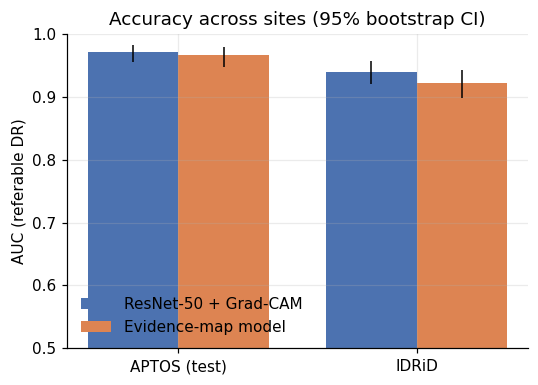

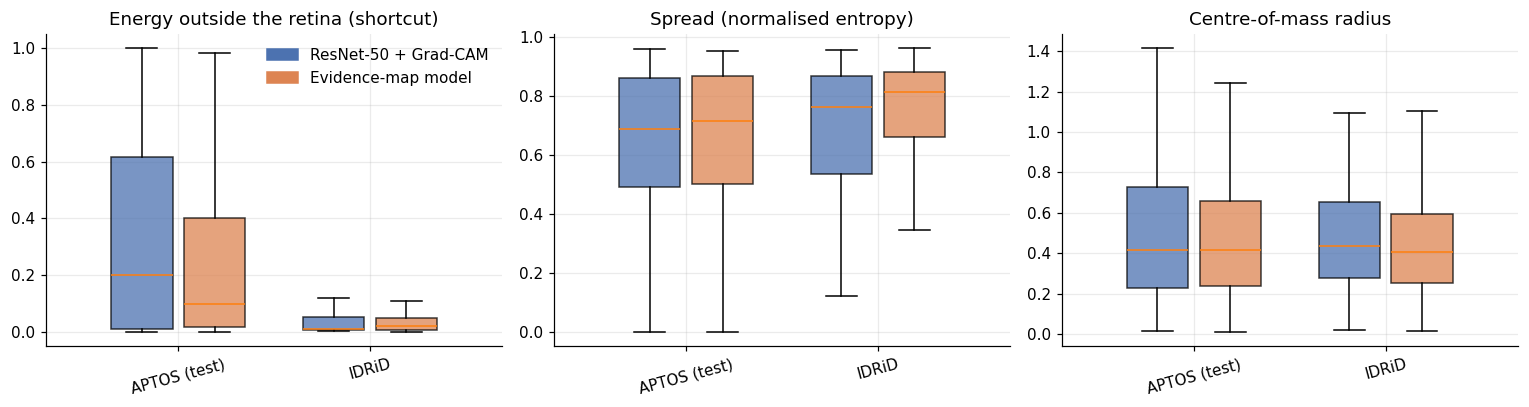

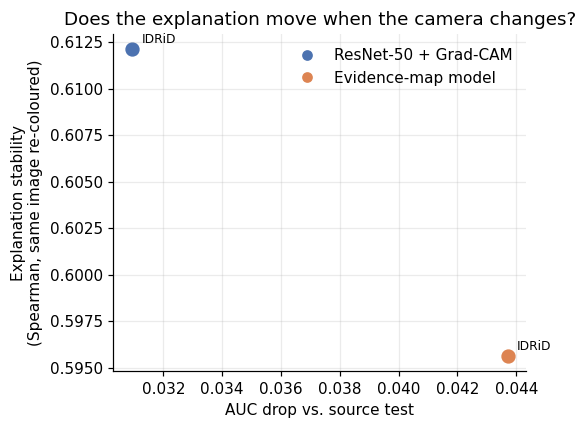

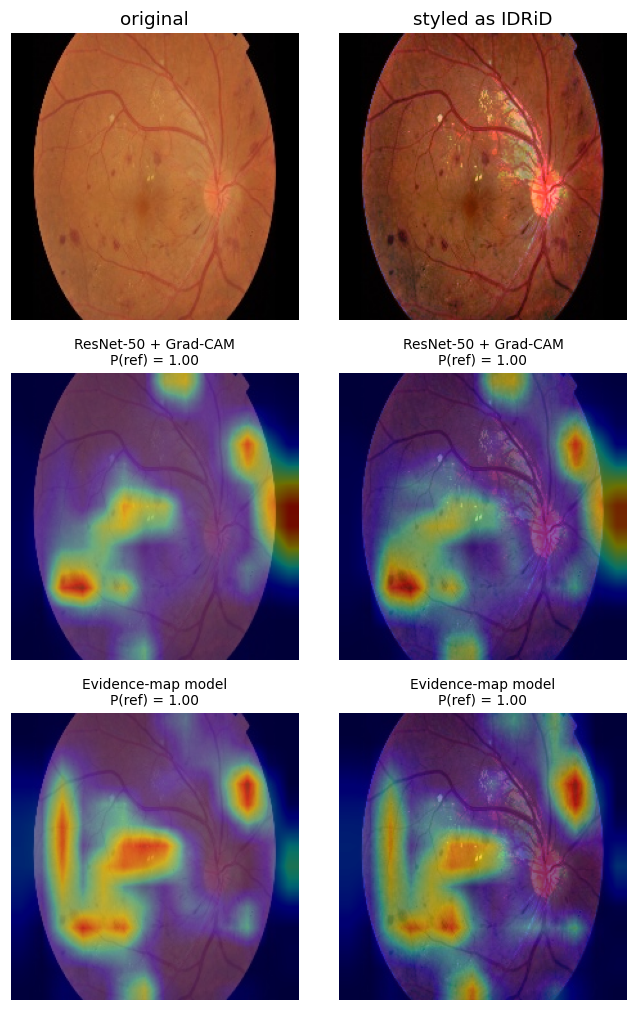

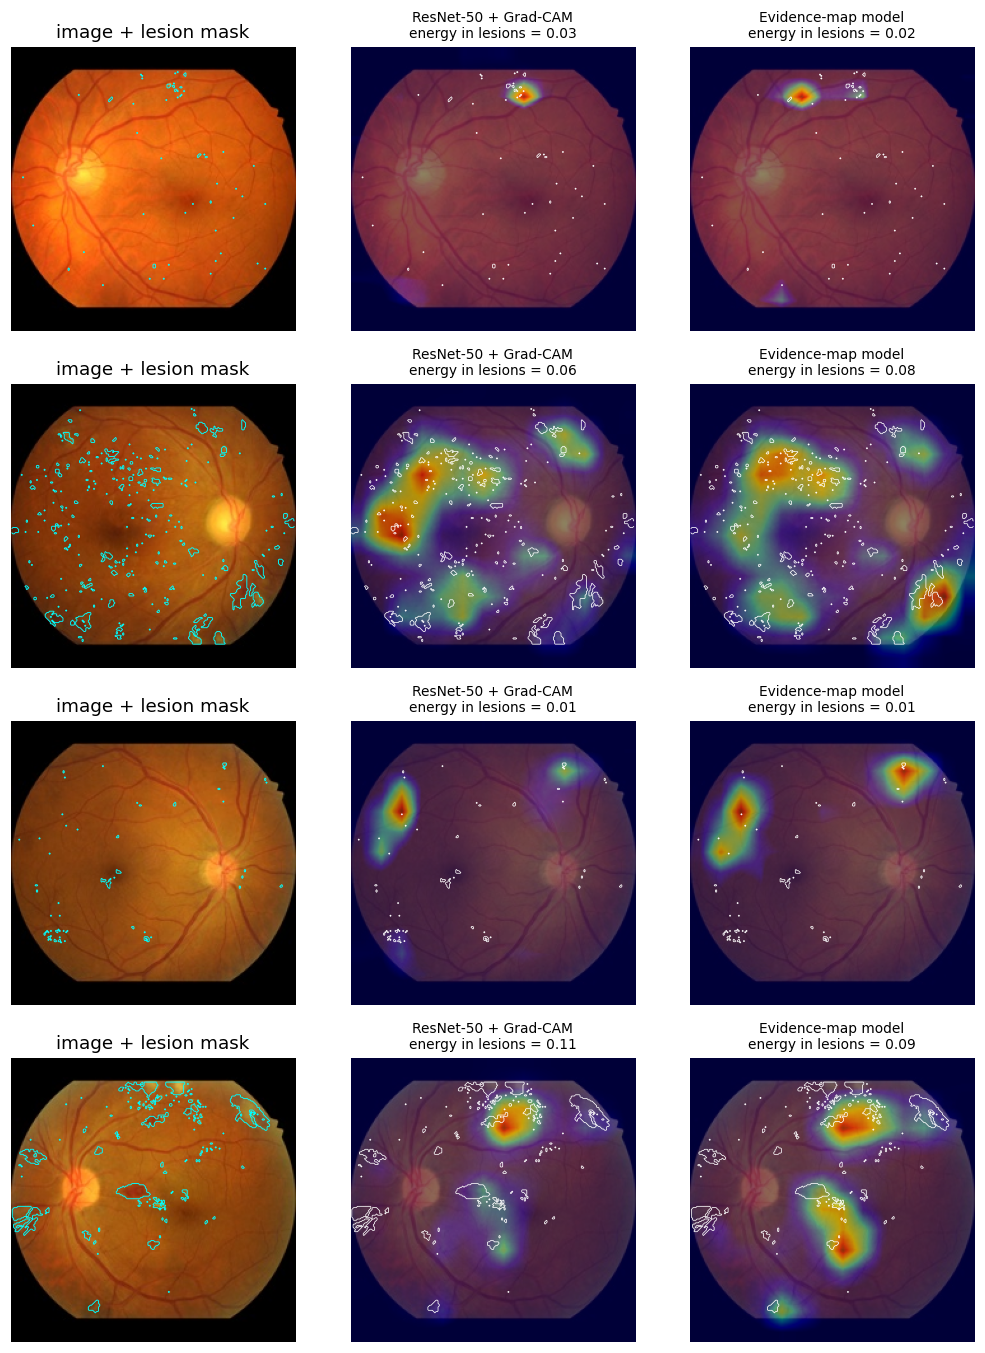

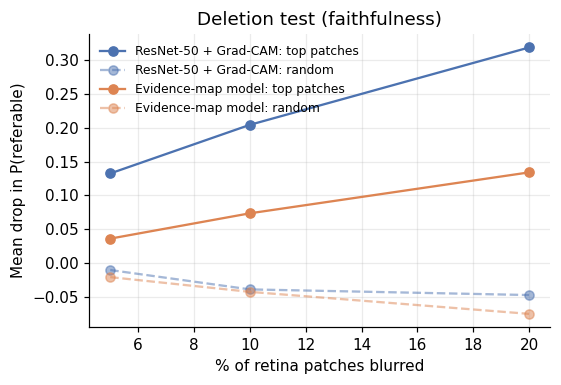

In [18]:
# --- Figures ---
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COL = {"gradcam": "#4C72B0", "evidence": "#DD8452"}
NAME = {"gradcam": "ResNet-50 + Grad-CAM", "evidence": "Evidence-map model"}
site_order = list(EVAL)

# 1) Performance per site
fig, ax = plt.subplots(figsize=(1.8 + 1.6 * len(site_order), 3.6))
w = 0.38
for j, kind in enumerate(TRAINED):
    d = PERF[PERF.model == kind].set_index("site").loc[site_order]
    xs = np.arange(len(site_order)) + (j - 0.5) * w
    ax.bar(xs, d["auc"], w, color=COL[kind], label=NAME[kind])
    ax.errorbar(xs, d["auc"], yerr=[d["auc"] - d["auc_lo"], d["auc_hi"] - d["auc"]], fmt="none", c="k", lw=1)
ax.set_xticks(range(len(site_order))); ax.set_xticklabels(site_order)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("AUC (referable DR)"); ax.set_title("Accuracy across sites (95% bootstrap CI)")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(OUT / "fig1_performance.png", bbox_inches="tight"); plt.show()

# 2) Where does the attribution go? (per site)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes, ["out_fov_energy", "entropy", "com_radius"],
                          ["Energy outside the retina (shortcut)", "Spread (normalised entropy)", "Centre-of-mass radius"]):
    for j, kind in enumerate(TRAINED):
        data = [ATTR[(ATTR.model == kind) & (ATTR.site == s)][col].values for s in site_order]
        pos = np.arange(len(site_order)) + (j - 0.5) * 0.38
        bp = ax.boxplot(data, positions=pos, widths=0.32, patch_artist=True, showfliers=False)
        for b in bp["boxes"]:
            b.set_facecolor(COL[kind]); b.set_alpha(0.75)
    ax.set_xticks(range(len(site_order))); ax.set_xticklabels(site_order, rotation=15)
    ax.set_title(title)
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=COL[k]) for k in TRAINED], [NAME[k] for k in TRAINED], frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig2_attribution_stats.png", bbox_inches="tight"); plt.show()

# 3) Accuracy vs. explanation stability under the camera change
if len(SWAP_SUM):
    fig, ax = plt.subplots(figsize=(5.2, 4))
    src_auc = PERF[PERF.site == SRC_KEY].set_index("model")["auc"]
    for kind in TRAINED:
        for s in EXTERNAL:
            auc_drop = src_auc[kind] - PERF[(PERF.model == kind) & (PERF.site == s)]["auc"].iloc[0]
            rho = SWAP_SUM[(SWAP_SUM.model == kind) & (SWAP_SUM.target_style == s)]["spearman"].iloc[0]
            ax.scatter(auc_drop, rho, s=70, color=COL[kind])
            ax.annotate(s, (auc_drop, rho), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xlabel("AUC drop vs. source test"); ax.set_ylabel("Explanation stability\n(Spearman, same image re-coloured)")
    ax.set_title("Does the explanation move when the camera changes?")
    ax.legend([plt.Line2D([], [], marker="o", ls="", color=COL[k]) for k in TRAINED], [NAME[k] for k in TRAINED], frameon=False)
    fig.tight_layout(); fig.savefig(OUT / "fig3_accuracy_vs_stability.png", bbox_inches="tight"); plt.show()

# 4) Qualitative: one image, re-coloured as each site, with both explanations
if len(SWAP_SUM):
    i = int(np.argmax(SWAP_MAPS[("gradcam", "original")][0]))        # a confident referable case
    cols = ["original"] + EXTERNAL
    fig, axes = plt.subplots(3, len(cols), figsize=(3.1 * len(cols), 9.3))
    axes = np.atleast_2d(axes).reshape(3, len(cols))
    for c, s in enumerate(cols):
        img = SRC_ARR[i] if s == "original" else STYLED[s][i]
        axes[0, c].imshow(img); axes[0, c].set_title(f"{s}" if s == "original" else f"styled as {s}")
        for rI, kind in enumerate(TRAINED, start=1):
            p, h = SWAP_MAPS[(kind, s)]
            axes[rI, c].imshow(img); axes[rI, c].imshow(h[i] / (h[i].max() + 1e-8), cmap="jet", alpha=0.45)
            axes[rI, c].set_title(f"{NAME[kind]}\nP(ref) = {p[i]:.2f}", fontsize=9)
    for a in axes.ravel():
        a.axis("off"); a.grid(False)
    fig.tight_layout(); fig.savefig(OUT / "fig4_site_swap_example.png", bbox_inches="tight"); plt.show()

# 5) Lesion grounding examples
if LESION is not None:
    ex = SEG_DF.head(4)
    fig, axes = plt.subplots(len(ex), 3, figsize=(9.5, 3.1 * len(ex)))
    axes = np.atleast_2d(axes)
    for rI, r in enumerate(ex.itertuples()):
        a = load_rgb(r.cpath); les = np.asarray(Image.open(r.lesion_path)) > 127
        axes[rI, 0].imshow(a); axes[rI, 0].contour(les, levels=[0.5], colors="cyan", linewidths=0.6)
        axes[rI, 0].set_title("image + lesion mask")
        x = normalize(to_tensor(a)[None]).to(DEVICE)
        for c, kind in enumerate(TRAINED, start=1):
            p, h = explain(TRAINED[kind], x)
            h = h[0].float().cpu().numpy()
            le = LESION[(LESION.model == kind) & (LESION.key == r.key)]["lesion_energy"].iloc[0]
            axes[rI, c].imshow(a); axes[rI, c].imshow(h / (h.max() + 1e-8), cmap="jet", alpha=0.45)
            axes[rI, c].contour(les, levels=[0.5], colors="white", linewidths=0.5)
            axes[rI, c].set_title(f"{NAME[kind]}\nenergy in lesions = {le:.2f}", fontsize=9)
    for a in axes.ravel():
        a.axis("off"); a.grid(False)
    fig.tight_layout(); fig.savefig(OUT / "fig5_lesion_grounding.png", bbox_inches="tight"); plt.show()

# 6) Deletion curves
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for kind in TRAINED:
    d = DEL_SUM.loc[kind]
    ax.plot(d.index * 100, d["top"], "-o", color=COL[kind], label=f"{NAME[kind]}: top patches")
    ax.plot(d.index * 100, d["random"], "--o", color=COL[kind], alpha=0.5, label=f"{NAME[kind]}: random")
ax.set_xlabel("% of retina patches blurred"); ax.set_ylabel("Mean drop in P(referable)")
ax.set_title("Deletion test (faithfulness)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "fig6_deletion.png", bbox_inches="tight"); plt.show()

In [19]:
# --- Auto-generated summary (for README / motivation letter notes) ---
def md_table(df):
    df = df.copy()
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(out)

lines = [f"# Results summary{' (DEMO data)' if DEMO_MODE else ''}", "",
         f"Source site: **{SOURCE_SITE}** · task: referable DR (grade ≥ 2) · image size {CFG['img_size']} px", "",
         "## Accuracy", md_table(PERF[["model", "site", "n", "prevalence", "auc", "auc_lo", "auc_hi", "sensitivity", "specificity"]]), "",
         "## Attribution statistics (median) and shift vs. source", md_table(SHIFT), ""]
if LESION is not None:
    lines += ["## Lesion grounding (IDRiD masks)", md_table(LES_SUM.reset_index()), ""]
if len(SWAP_SUM):
    lines += ["## Site-swap consistency (same image, re-coloured)", md_table(SWAP_SUM), ""]
lines += ["## Deletion test", md_table(DEL_SUM.reset_index()), ""]

# short automatic reading of the results
notes = []
for kind in TRAINED:
    sp = PERF[PERF.model == kind].set_index("site")["auc"]
    worst = sp.drop(SRC_KEY).idxmin() if len(sp) > 1 else None
    if worst:
        notes.append(f"- {NAME[kind]}: AUC {sp[SRC_KEY]:.3f} on the source test set, lowest external AUC {sp[worst]:.3f} ({worst}).")
    if len(SWAP_SUM):
        r = SWAP_SUM[SWAP_SUM.model == kind]["spearman"].mean()
        notes.append(f"  Mean explanation stability under re-colouring (Spearman): {r:.3f}.")
    o = SHIFT[(SHIFT.model == kind) & (SHIFT.site == SRC_KEY)]["out_fov_energy_median"].iloc[0]
    notes.append(f"  Median attribution energy outside the retina on the source site: {o:.3f}.")
lines += ["## Automatic notes (check them yourself before writing anything)"] + notes
(OUT / "summary.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))
print("\nSaved all tables and figures to:", OUT)

# Results summary

Source site: **APTOS** · task: referable DR (grade ≥ 2) · image size 224 px

## Accuracy
| model | site | n | prevalence | auc | auc_lo | auc_hi | sensitivity | specificity |
|---|---|---|---|---|---|---|---|---|
| gradcam | APTOS (test) | 550 | 0.405 | 0.972 | 0.956 | 0.983 | 0.870 | 0.948 |
| gradcam | IDRiD | 516 | 0.626 | 0.941 | 0.921 | 0.958 | 0.650 | 0.995 |
| evidence | APTOS (test) | 550 | 0.405 | 0.966 | 0.948 | 0.979 | 0.919 | 0.917 |
| evidence | IDRiD | 516 | 0.626 | 0.923 | 0.899 | 0.943 | 0.814 | 0.891 |

## Attribution statistics (median) and shift vs. source
| model | site | out_fov_energy_median | entropy_median | com_radius_median | out_fov_energy_wasserstein | out_fov_energy_ks_p | entropy_wasserstein | entropy_ks_p | com_radius_wasserstein | com_radius_ks_p |
|---|---|---|---|---|---|---|---|---|---|---|
| gradcam | APTOS (test) | 0.199 | 0.690 | 0.416 | nan | nan | nan | nan | nan | nan |
| gradcam | IDRiD | 0.010 | 0.762 | 0.436 | 0.201 | 0.000

## How to read the results

- **Accuracy (fig 1).** A drop on external sites is expected. The interesting case is when AUC stays similar but the explanation changes.
- **Energy outside the retina (fig 2, left).** Anything clearly above ~0.02 means the model uses the image border, camera text or the black background. In DEMO mode the source site has a planted white marker, so this value should be high there for at least one model.
- **Site-swap stability (fig 3, fig 4).** The *same* image is shown with another site's colour distribution. Spearman close to 1 means the explanation survives the camera change. A low value together with a small AUC change is the key "accuracy holds but evidence moves" finding.
- **Lesion grounding (fig 5).** `lift` > 1 means the model puts more attribution on lesions than their area would predict. `pointing_game` is the share of images where the hottest pixel falls on (or within a few pixels of) a lesion.
- **Deletion test (fig 6).** If blurring the top-attributed patches does not hurt more than blurring random patches, the explanation is not faithful to the model.

## Limitations (write these honestly)

- Site-swap uses colour/contrast matching only. Real cameras also differ in resolution, blur, field of view and compression.
- DR grading conventions differ between datasets, so external AUC mixes device shift with label shift.
- One training seed. For a paper, repeat with 3 seeds and report mean ± std.
- Grad-CAM and the evidence map have different resolutions of meaning; compare trends, not absolute values.

## Next steps

1. Add a third explanation method (e.g. Integrated Gradients) and a ViT backbone.
2. Add resolution / blur / JPEG differences to the site-swap test.
3. Train with a consistency loss that keeps explanations stable across simulated sites, and test whether it improves external AUC.